# Student_Bayes · MT2002 Statistical Modeling · Assignment 3
**Mohammad Rohaan · 22I-2327 · Section A · Fall 2026**

I use the original `Syn_student.csv` in `data/`, resolved from the repository or notebook directory. Regression describes quiz scores, and classification predicts student type. Both analyses use the recorded habits as predictors.

To rerun, use a Python kernel with NumPy, pandas, Matplotlib, seaborn, SciPy, scikit-learn, PyMC and ArviZ. The reported posterior intervals use a 94% highest-density interval (HDI).

Nutpie is optional. It speeds up NUTS sampling when installed.

Run environment: Python 3.12, PyMC 5.28.5 with Nutpie 0.16.11, ArviZ 0.23.4, NumPy 2.3.5, pandas 2.3.3, Matplotlib 3.10.8 and seaborn 0.13.2.

In [1]:
from importlib.util import find_spec
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
import pytensor.tensor as pt
import arviz as az
from IPython.display import display
from scipy.special import softmax
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
az.rcParams["stats.ci_prob"] = 0.94

def sample():
    # Nutpie is an optional faster NUTS engine. PyMC's built-in NUTS also works.
    engine = "nutpie" if find_spec("nutpie") else "pymc"
    return pm.sample(draws=1000, tune=1500, chains=4,
                     cores=4 if engine == "nutpie" else 1, nuts_sampler=engine,
                     target_accept=0.95, random_seed=SEED, progressbar=False)

def draws(fit, name):
    values = fit.posterior[name].values
    return values.reshape((-1,) + values.shape[2:])

def interval(values):
    return az.hdi(np.asarray(values), hdi_prob=0.94)

def estimate(values):
    lo, hi = interval(values)
    return f"{np.mean(values):.3f} (94% HDI {lo:.3f} to {hi:.3f})"

def excludes_zero(values):
    lo, hi = interval(values)
    return lo > 0 or hi < 0

def summary(fit, names):
    display(az.summary(fit, var_names=names, hdi_prob=0.94, round_to=3))
    print("Divergences:", int(fit.sample_stats["diverging"].sum()))

def trace(fit, names, title):
    axes = az.plot_trace(fit, var_names=names, compact=True)
    axes[0, 0].figure.suptitle(title, y=1.02)
    for density, chain in axes:
        density.set(xlabel="Parameter value", ylabel="Density")
        chain.set(xlabel="Draw", ylabel="Parameter value")
    plt.tight_layout()
    plt.show()

## Data and exploration
The five columns are checked before any model is fit. The same observations are used for the descriptive and regression analyses. Only the classification task uses a train/test split.

In [2]:
students = pd.read_csv(next(p for p in [Path("data/Syn_student.csv"), Path("../data/Syn_student.csv")] if p.exists()))
features = ["study_hours", "sleep_hours", "social_time"]
numeric = features + ["quiz_score"]
classes = ["bad", "good", "excellent"]
assert students.shape == (150, 5)
assert set(students.columns) == set(numeric + ["student_type"])
assert set(students["student_type"]) == set(classes)

print("Shape:", students.shape)
print("Columns:", students.columns.tolist())
display(students.head())
display(pd.DataFrame({"dtype": students.dtypes.astype(str),
                      "missing": students.isna().sum()}))
print("Exact duplicate rows:", students.duplicated().sum())
display(students[numeric].describe().round(3))
counts = students["student_type"].value_counts().reindex(classes)
display(counts.rename("students").to_frame())
assert students[numeric].notna().all().all()

Shape: (150, 5)
Columns: ['study_hours', 'sleep_hours', 'social_time', 'quiz_score', 'student_type']


,study_hours,sleep_hours,social_time,quiz_score,student_type
0,8.248357,3.162042,1.292315,9.125246,excellent
1,7.930868,2.807459,1.789677,9.173224,excellent
2,8.323844,2.661539,1.828643,8.659988,excellent
3,8.761515,3.305838,1.598861,9.116127,excellent
4,7.882923,3.515500,1.919357,9.146536,excellent


,dtype,missing
study_hours,float64,0
sleep_hours,float64,0
social_time,float64,0
quiz_score,float64,0
student_type,object,0


Exact duplicate rows: 0


,study_hours,sleep_hours,social_time,quiz_score
count,150.000,150.000,150.000,150.000
mean,5.479,5.156,3.956,6.549
std,2.078,1.618,1.656,2.112
min,1.966,1.690,1.041,2.894
25%,3.346,3.331,2.269,4.259
50%,5.601,5.783,4.002,6.562
75%,7.533,6.417,5.569,8.615
max,8.926,7.567,6.955,10.360


,students
student_type,
bad,50
good,50
excellent,50


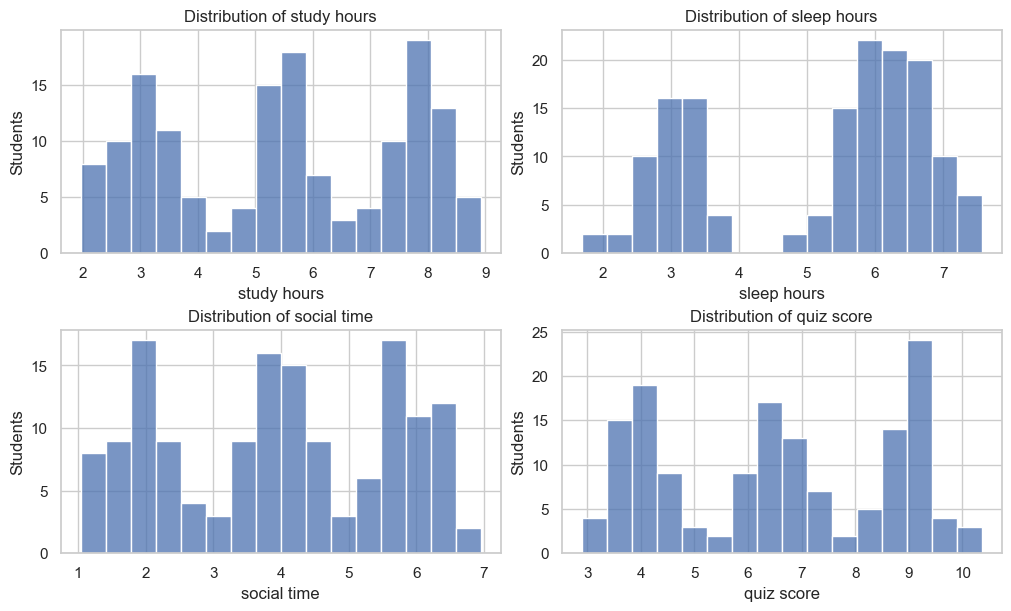

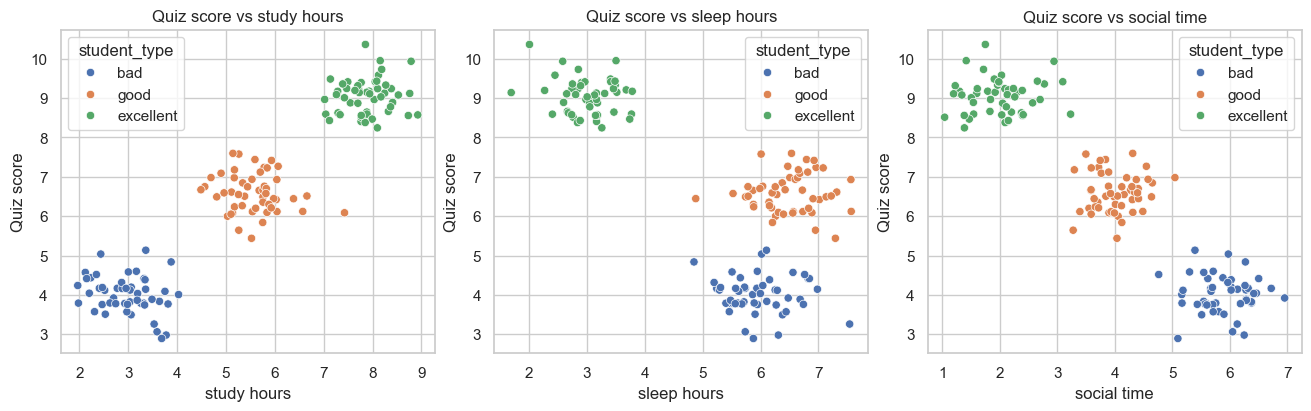

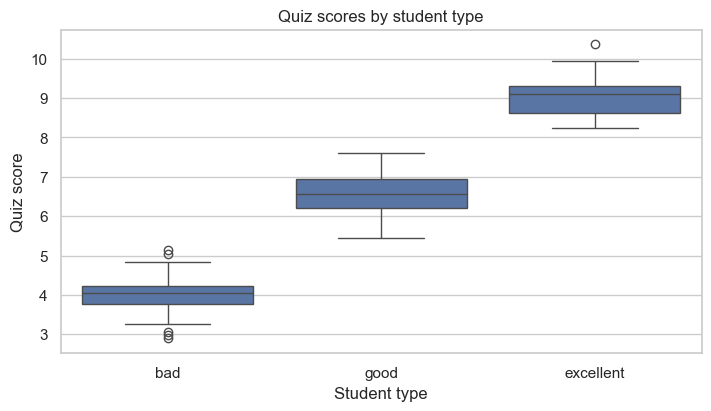

,study_hours,sleep_hours,social_time,quiz_score
student_type,,,,
bad,3.01,5.92,5.84,4.04
good,5.60,6.52,4.00,6.56
excellent,7.88,3.02,2.01,9.10


,Values outside 1.5 IQR fences
study_hours,0
sleep_hours,0
social_time,0
quiz_score,0


,study_hours,sleep_hours,social_time,quiz_score,student_type


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
for ax, col in zip(axes.flat, numeric):
    sns.histplot(students[col], bins=16, ax=ax)
    ax.set(title=f"Distribution of {col.replace('_', ' ')}",
           xlabel=col.replace("_", " "), ylabel="Students")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, col in zip(axes, features):
    sns.scatterplot(data=students, x=col, y="quiz_score", hue="student_type",
                    hue_order=classes, ax=ax)
    ax.set(title=f"Quiz score vs {col.replace('_', ' ')}",
           xlabel=col.replace("_", " "), ylabel="Quiz score")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
sns.boxplot(data=students, x="student_type", y="quiz_score", order=classes, ax=ax)
ax.set(title="Quiz scores by student type", xlabel="Student type", ylabel="Quiz score")
plt.show()
display(students.groupby("student_type")[numeric].median().reindex(classes).round(2))

q1, q3 = students[numeric].quantile(.25), students[numeric].quantile(.75)
iqr = q3 - q1
outside = ((students[numeric] < q1 - 1.5*iqr) |
           (students[numeric] > q3 + 1.5*iqr))
display(outside.sum().rename("Values outside 1.5 IQR fences").to_frame())
display(students.loc[outside.any(axis=1)])

There are 150 rows and 50 students in each category. No value is missing, and no row is an exact duplicate. The median quiz score is 4.04 for bad, 6.56 for good, and 9.10 for excellent. The scatter plots show higher scores as study time rises and lower scores as social time or sleep rises. Students in the same category still vary. No numeric value is beyond its marginal 1.5-IQR fences, though students can still have large regression residuals. All rows are kept.

## Part 1 · Covariance and Pearson correlation
Covariance carries the units of both variables. Changing study hours to minutes multiplies its covariance with score by 60. Pearson correlation divides covariance by the two sample standard deviations, so changing to minutes leaves it unchanged. It ranges from −1 to +1. A correlation of zero indicates no sample linear association, and a nonlinear relationship can still exist.

,study_hours,sleep_hours,social_time,quiz_score
study_hours,4.316,-2.339,-3.220,4.119
sleep_hours,-2.339,2.618,1.958,-2.486
social_time,-3.220,1.958,2.742,-3.272
quiz_score,4.119,-2.486,-3.272,4.459


,study_hours,sleep_hours,social_time,quiz_score
study_hours,1.000,-0.696,-0.936,0.939
sleep_hours,-0.696,1.000,0.731,-0.728
social_time,-0.936,0.731,1.000,-0.936
quiz_score,0.939,-0.728,-0.936,1.000


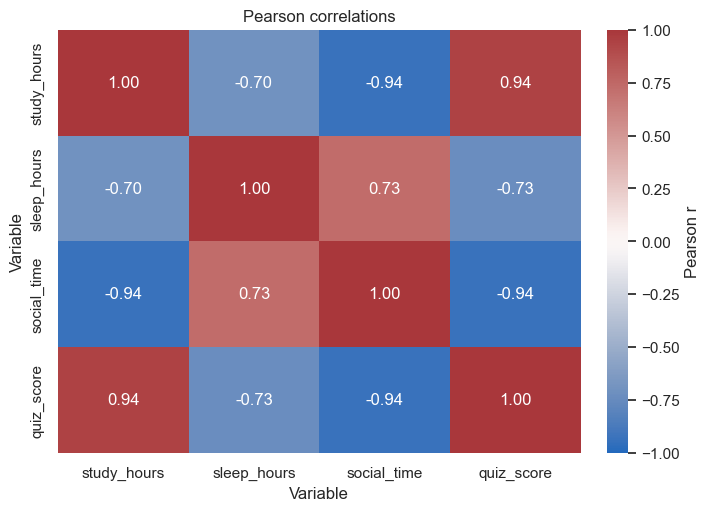

,Correlation with quiz score
study_hours,0.939
sleep_hours,-0.728
social_time,-0.936


Strongest predictor pair: study_hours and social_time, r = -0.936.


In [4]:
covariance = students[numeric].cov()
correlation = students[numeric].corr(method="pearson")
display(covariance.round(3))
display(correlation.round(3))
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
sns.heatmap(correlation, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            cmap="vlag", ax=ax, cbar_kws={"label": "Pearson r"})
ax.set(title="Pearson correlations", xlabel="Variable", ylabel="Variable")
plt.show()

score_corr = correlation.loc[features, "quiz_score"]
strongest = score_corr.abs().idxmax()
pairs = {(a, b): correlation.loc[a, b] for i, a in enumerate(features)
         for b in features[i+1:]}
pair = max(pairs, key=lambda p: abs(pairs[p]))
display(score_corr.round(3).to_frame("Correlation with quiz score"))
print(f"Strongest predictor pair: {pair[0]} and {pair[1]}, r = {pairs[pair]:.3f}.")

When two predictors move together, the data contain fewer examples where one changes and the other stays fixed. This makes their separate regression coefficients harder to estimate.

### Bayesian correlation
I model study hours and quiz scores jointly. Each mean has a Normal prior centered at 5 with SD 5, and each marginal SD has a HalfNormal(3) prior. The Uniform(−1, 1) prior for $\rho$ allows either direction. The covariance is $\rho\sigma_1\sigma_2$. The joint bivariate Normal density equals $p(\mathrm{study})p(\mathrm{score}\mid\mathrm{study})$. I use those two Normal terms to evaluate the same joint likelihood without repeated matrix solves.

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
center[study_hours],5.487,0.173,5.153,5.799,0.005,0.003,1215.967,1646.658,1.001
center[quiz_score],6.555,0.173,6.234,6.881,0.005,0.003,1240.172,1642.199,1.001
scale[study_hours],2.084,0.119,1.871,2.311,0.003,0.002,1425.328,1786.987,1.001
scale[quiz_score],2.119,0.120,1.917,2.366,0.003,0.002,1476.330,1777.603,1.001
rho,0.937,0.010,0.917,0.954,0.000,0.000,1723.169,2011.181,1.003


Divergences: 0


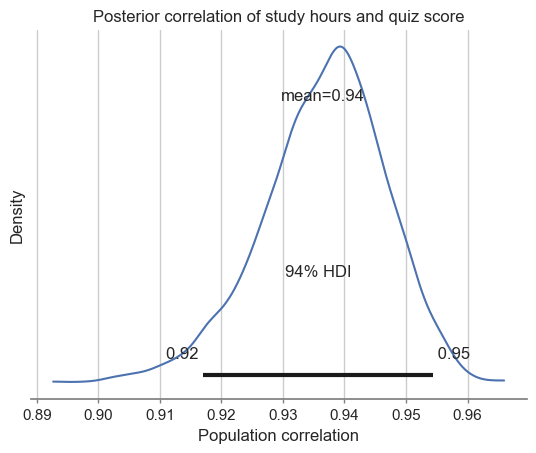

Sample Pearson r: 0.939
Bayesian rho: 0.937 (94% HDI 0.917 to 0.954)
Direction agrees with sample Pearson: True


In [5]:
paired = students[["study_hours", "quiz_score"]].to_numpy()
with pm.Model(coords={"measure": ["study_hours", "quiz_score"]}) as corr_model:
    center = pm.Normal("center", 5, 5, dims="measure")
    scale = pm.HalfNormal("scale", 3, dims="measure")
    rho = pm.Uniform("rho", -1, 1)
    # The joint bivariate Normal density factors into a marginal
    # Normal for study hours and a conditional Normal for quiz score.
    study, score = paired.T
    pm.Normal("study", mu=center[0], sigma=scale[0], observed=study)
    conditional_mean = center[1] + rho * scale[1] / scale[0] * (study - center[0])
    conditional_sd = scale[1] * pt.sqrt(1 - rho**2)
    pm.Normal("score_given_study", mu=conditional_mean, sigma=conditional_sd, observed=score)
    corr_fit = sample()

summary(corr_fit, ["center", "scale", "rho"])
rho_draws = draws(corr_fit, "rho")
ax = az.plot_posterior(corr_fit, var_names=["rho"], hdi_prob=.94)
ax.set(title="Posterior correlation of study hours and quiz score",
       xlabel="Population correlation", ylabel="Density")
plt.show()
print("Sample Pearson r:", round(score_corr["study_hours"], 3))
print("Bayesian rho:", estimate(rho_draws))
same_direction = np.sign(rho_draws.mean()) == np.sign(score_corr["study_hours"])
print("Direction agrees with sample Pearson:", same_direction)

The Bayesian estimate of the study–score correlation is **0.937 (94% HDI 0.917 to 0.954)**, close to the sample Pearson correlation of **0.939**. Both indicate a strong positive linear association in this dataset. The HDI is conditional on the bivariate normal model, which summarizes the overall pattern even though the scatter plot shows three clusters.

## Part 2 · Regression for quiz score
I center study hours in the linear models so the intercept describes a student near the middle of the observed study range. This leaves the slope per hour unchanged. The quiz-score prior for the intercept is Normal(5, 5), each linear slope has Normal(0, 2) on its model's predictor scale, and residual scale has HalfNormal(3). These allow positive or negative effects and residual noise measured in quiz-score points.

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,6.546,0.059,6.441,6.659,0.001,0.001,3476.637,2738.491,1.0
beta,0.954,0.029,0.899,1.008,0.000,0.000,3819.093,2775.565,1.0
sigma,0.735,0.043,0.656,0.815,0.001,0.001,3477.814,2746.566,1.0


Divergences: 0


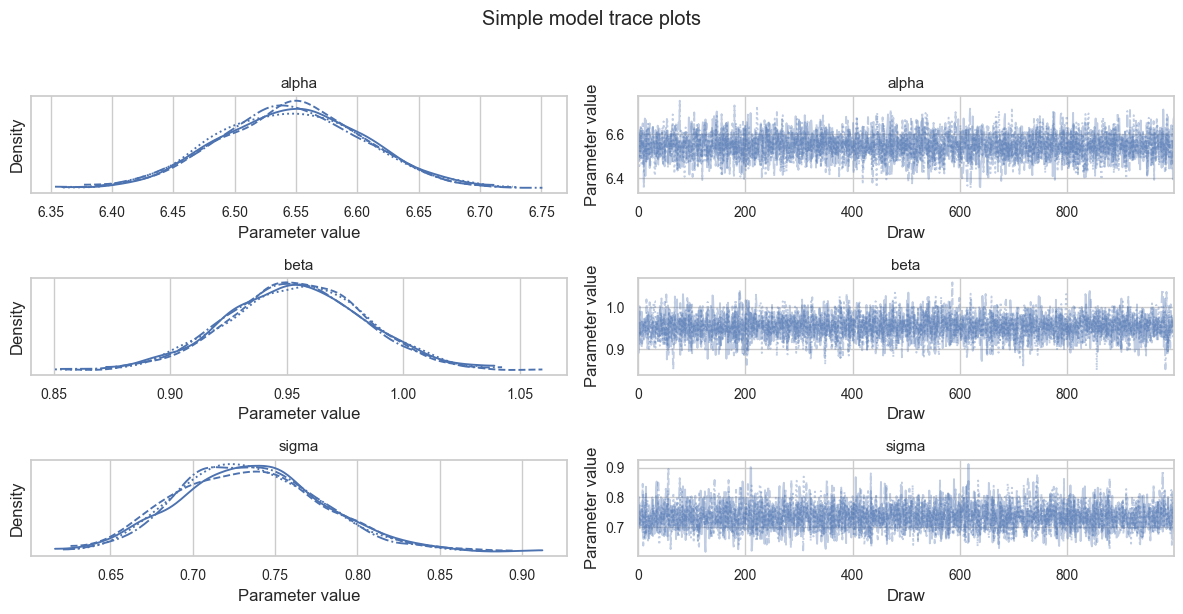

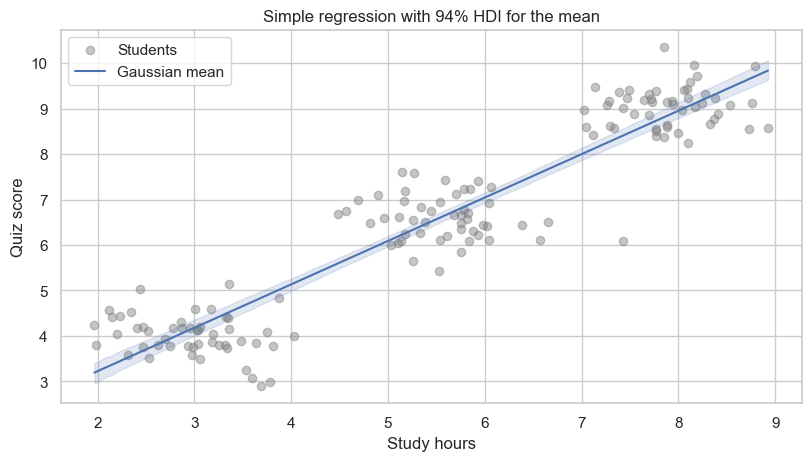

Score points per additional study hour: 0.954 (94% HDI 0.899 to 1.008)
Posterior P(slope > 0): 1.0000
Expected quiz score at 4 study hours: 5.135 (94% HDI 4.991 to 5.265)
Expected quiz score at 8 study hours: 8.952 (94% HDI 8.792 to 9.137)


In [6]:
x = students["study_hours"].to_numpy()
y = students["quiz_score"].to_numpy()
x_center = x.mean()
xc = x - x_center
grid = np.linspace(x.min(), x.max(), 120)
gc = grid - x_center

with pm.Model() as simple_model:
    alpha = pm.Normal("alpha", 5, 5)
    beta = pm.Normal("beta", 0, 2)
    sigma = pm.HalfNormal("sigma", 3)
    mu = pm.Deterministic("mu", alpha + beta*xc)
    pm.Normal("score", mu, sigma, observed=y)
    simple_fit = sample()

summary(simple_fit, ["alpha", "beta", "sigma"])
trace(simple_fit, ["alpha", "beta", "sigma"], "Simple model trace plots")

def curve(fit, centered_grid, slope="beta", quadratic=False):
    line = draws(fit, "alpha")[:, None] + draws(fit, slope)[:, None]*centered_grid
    if quadratic:
        line = line + draws(fit, "beta2")[:, None]*centered_grid**2
    return line

def plot_curves(title, fitted_curves):
    fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
    ax.scatter(x, y, alpha=.45, color="gray", label="Students")
    for label, values in fitted_curves.items():
        bounds = np.array([interval(col) for col in values.T])
        line, = ax.plot(grid, values.mean(axis=0), label=label)
        ax.fill_between(grid, bounds[:, 0], bounds[:, 1], color=line.get_color(), alpha=.16)
    ax.set(title=title, xlabel="Study hours", ylabel="Quiz score")
    ax.legend()
    plt.show()

simple_curve = curve(simple_fit, gc)
plot_curves("Simple regression with 94% HDI for the mean", {"Gaussian mean": simple_curve})
simple_beta = draws(simple_fit, "beta")
print("Score points per additional study hour:", estimate(simple_beta))
print(f"Posterior P(slope > 0): {(simple_beta > 0).mean():.4f}")
for hours, expected in zip([4, 8], curve(simple_fit, np.array([4, 8])-x_center).T):
    print(f"Expected quiz score at {hours} study hours:", estimate(expected))

The slope expresses an expected score difference per additional study hour. The intervals at 4 and 8 hours describe uncertainty in the fitted mean; a new student's score also varies around that mean.

### Robust regression
The Student-t model uses the same mean equation and priors as the simple fit. I set $\nu=2+\operatorname{Exponential}(1/10)$, which allows heavier tails and keeps the residual variance finite. Heavy tails let unusually large residuals have less influence on the line.

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,6.564,0.061,6.443,6.674,0.001,0.001,4647.393,2674.567,1.001
beta,0.955,0.029,0.903,1.009,0.000,0.000,4427.534,3112.737,1.000
sigma,0.685,0.050,0.589,0.780,0.001,0.001,3264.100,2918.867,1.001
nu,17.358,10.176,4.060,35.857,0.168,0.241,3579.910,3128.582,1.000


Divergences: 0
Gaussian slope: 0.954 (94% HDI 0.899 to 1.008)
Student-t slope: 0.955 (94% HDI 0.903 to 1.009)


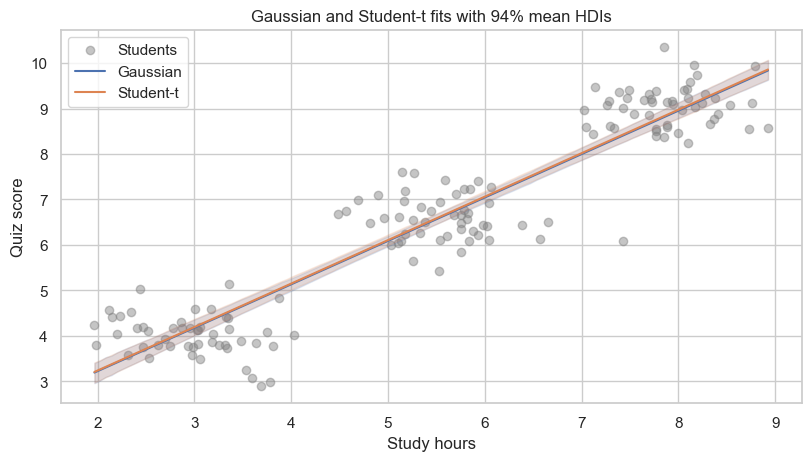

In [7]:
with pm.Model() as robust_model:
    alpha = pm.Normal("alpha", 5, 5)
    beta = pm.Normal("beta", 0, 2)
    sigma = pm.HalfNormal("sigma", 3)
    nu = pm.Deterministic("nu", 2 + pm.Exponential("nu_minus_two", 1/10))
    mu = pm.Deterministic("mu", alpha + beta*xc)
    pm.StudentT("score", nu=nu, mu=mu, sigma=sigma, observed=y)
    robust_fit = sample()

summary(robust_fit, ["alpha", "beta", "sigma", "nu"])
robust_beta = draws(robust_fit, "beta")
print("Gaussian slope:", estimate(simple_beta))
print("Student-t slope:", estimate(robust_beta))
plot_curves("Gaussian and Student-t fits with 94% mean HDIs",
            {"Gaussian": simple_curve, "Student-t": curve(robust_fit, gc)})

The Gaussian slope is **0.954 (94% HDI 0.899 to 1.008)** and the Student-t slope is **0.955 (94% HDI 0.903 to 1.009)** score points per hour. The posterior means differ by 0.001 point per hour, and the uncertainty intervals overlap. The Student-t degrees of freedom are 17.358 (94% HDI 4.060 to 35.857). Both fits support a positive study–score association.

### Quadratic regression
I square the centered study hours. With $x$ measured in hours, $\beta_2$ describes curvature in points per hour squared, and $\beta_1$ is the slope at average study hours. I use a Normal(0, 0.5) prior for the quadratic term because squaring hours increases the size of the predictor, especially at the extremes.

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,6.457,0.094,6.281,6.637,0.002,0.001,1642.238,2401.635,1.002
beta1,0.957,0.030,0.903,1.013,0.000,0.000,3708.759,2741.222,1.001
beta2,0.021,0.017,-0.010,0.053,0.000,0.000,1581.644,2171.682,1.003
sigma,0.734,0.042,0.659,0.815,0.001,0.001,4000.491,2891.952,1.004


Divergences: 0


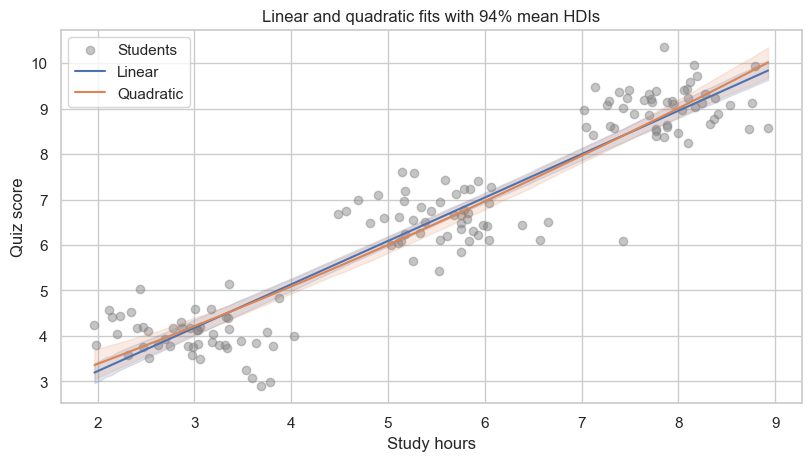

Quadratic coefficient: 0.021 (94% HDI -0.010 to 0.053)
Quadratic HDI excludes zero: False


In [8]:
with pm.Model() as quadratic_model:
    alpha = pm.Normal("alpha", 5, 5)
    beta1 = pm.Normal("beta1", 0, 2)
    beta2 = pm.Normal("beta2", 0, .5)
    sigma = pm.HalfNormal("sigma", 3)
    mu = pm.Deterministic("mu", alpha + beta1*xc + beta2*xc**2)
    pm.Normal("score", mu, sigma, observed=y)
    quadratic_fit = sample()

summary(quadratic_fit, ["alpha", "beta1", "beta2", "sigma"])
quad_beta = draws(quadratic_fit, "beta2")
plot_curves("Linear and quadratic fits with 94% mean HDIs",
            {"Linear": simple_curve, "Quadratic": curve(quadratic_fit, gc, "beta1", True)})
print("Quadratic coefficient:", estimate(quad_beta))
print("Quadratic HDI excludes zero:", excludes_zero(quad_beta))

The quadratic coefficient is **0.021 (94% HDI -0.010 to 0.053)**. Its HDI includes zero, so the observed curvature is weak evidence for changing the straight-line description. The overlay shows how much the curve changes fitted scores over the observed hours. I also compare fit and predictive checks below before choosing a model.

### Multiple linear regression
For each predictor I subtract the full-sample mean and divide by its sample SD (ddof=1). The outcome stays in points, so each coefficient describes the expected score change for a one-SD increase in its predictor with the other two held fixed.

,mean,sample SD
study_hours,5.479459,2.077554
sleep_hours,5.155557,1.617931
social_time,3.955714,1.655997


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,6.548,0.053,6.448,6.650,0.001,0.001,3804.753,2331.600,1.001
beta[study_hours],1.053,0.150,0.759,1.323,0.004,0.003,1274.461,1543.312,1.002
beta[sleep_hours],-0.172,0.078,-0.315,-0.023,0.001,0.001,2886.128,2547.967,1.002
beta[social_time],-0.865,0.160,-1.164,-0.574,0.005,0.003,1233.135,1434.667,1.001
sigma,0.644,0.039,0.572,0.713,0.001,0.001,3823.707,2321.704,1.000


Divergences: 0


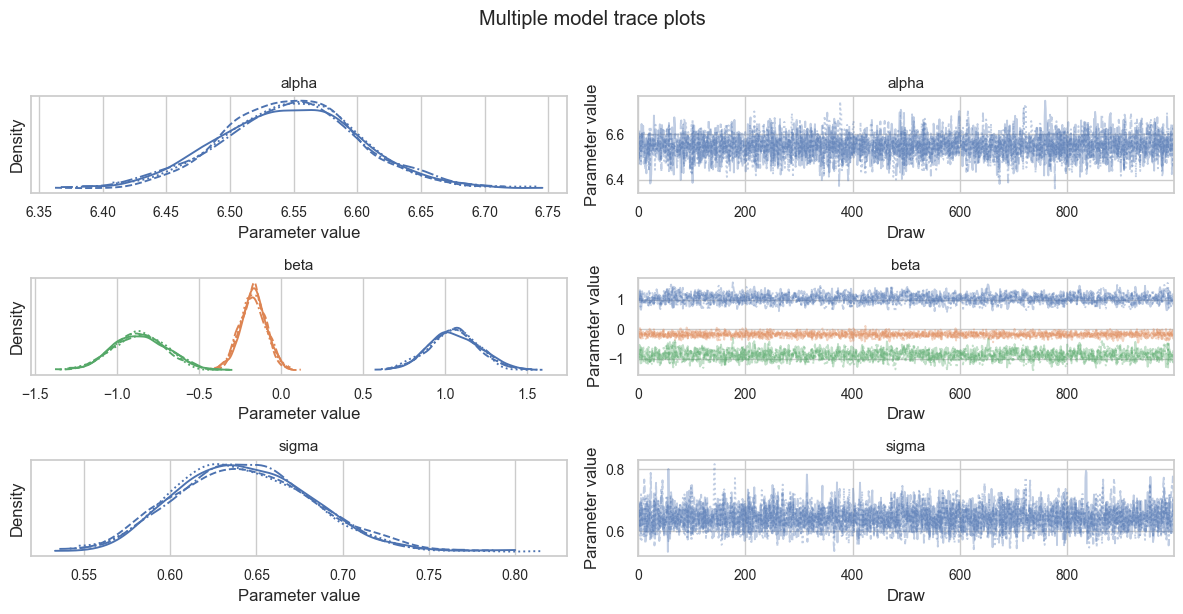

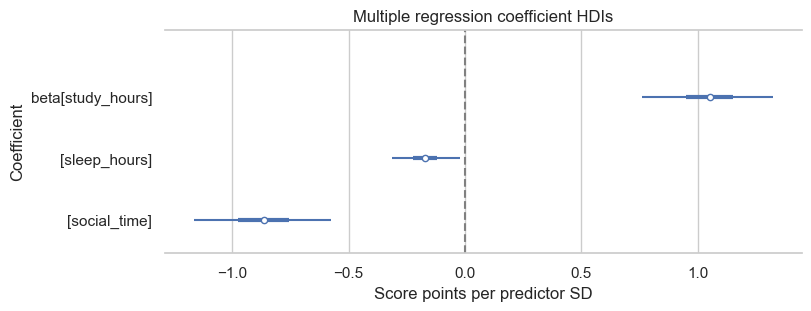

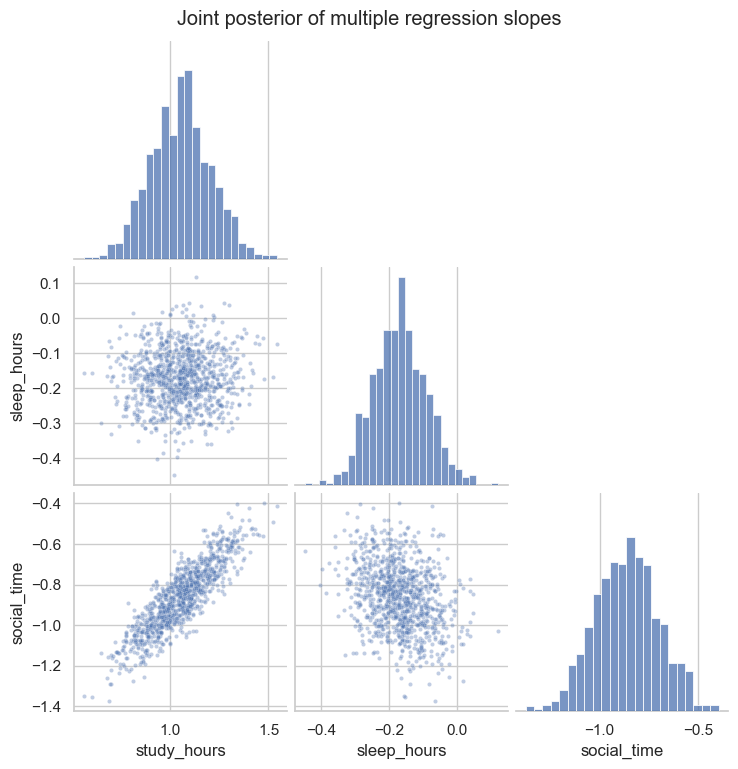

,study_hours,sleep_hours,social_time
study_hours,1.000,0.033,0.872
sleep_hours,0.033,1.000,-0.334
social_time,0.872,-0.334,1.000


study_hours holding the other two fixed: 1.053 (94% HDI 0.759 to 1.323)
sleep_hours holding the other two fixed: -0.172 (94% HDI -0.315 to -0.023)
social_time holding the other two fixed: -0.865 (94% HDI -1.164 to -0.574)
Adjusted study slope per hour: 0.507 (94% HDI 0.365 to 0.637)
Simple study slope per hour:   0.954 (94% HDI 0.899 to 1.008)


In [9]:
predictor_mean = students[features].mean()
predictor_sd = students[features].std(ddof=1)
X = ((students[features]-predictor_mean)/predictor_sd).to_numpy()
display(pd.DataFrame({"mean": predictor_mean, "sample SD": predictor_sd}))

with pm.Model(coords={"predictor": features}) as multiple_model:
    alpha = pm.Normal("alpha", 5, 5)
    beta = pm.Normal("beta", 0, 2, dims="predictor")
    sigma = pm.HalfNormal("sigma", 3)
    mu = pm.Deterministic("mu", alpha + X @ beta)
    pm.Normal("score", mu, sigma, observed=y)
    multiple_fit = sample()

summary(multiple_fit, ["alpha", "beta", "sigma"])
trace(multiple_fit, ["alpha", "beta", "sigma"], "Multiple model trace plots")
multiple_beta = draws(multiple_fit, "beta")
fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
az.plot_forest(multiple_fit, var_names=["beta"], combined=True, hdi_prob=.94, ax=ax)
ax.axvline(0, color="gray", linestyle="--")
ax.set(title="Multiple regression coefficient HDIs", xlabel="Score points per predictor SD",
       ylabel="Coefficient")
plt.show()

coef_pairs = pd.DataFrame(multiple_beta, columns=features)
g = sns.pairplot(coef_pairs.iloc[::4], corner=True, diag_kind="hist",
                 plot_kws={"s": 9, "alpha": .35})
g.figure.suptitle("Joint posterior of multiple regression slopes", y=1.02)
for ax in g.diag_axes:
    ax.set_ylabel("Draws")
plt.show()
display(coef_pairs.corr().round(3))
for name, posterior in zip(features, multiple_beta.T):
    print(f"{name} holding the other two fixed:", estimate(posterior))
adjusted_study = multiple_beta[:, 0]/predictor_sd["study_hours"]
print("Adjusted study slope per hour:", estimate(adjusted_study))
print("Simple study slope per hour:  ", estimate(simple_beta))

- **Study hours** changes the fitted score by 1.053 (94% HDI 0.759 to 1.323) points per SD with the other two habits held fixed. The interval supports a positive association.
- **Sleep hours** changes the fitted score by -0.172 (94% HDI -0.315 to -0.023) points per SD with the other two habits held fixed. The interval supports a negative association.
- **Social time** changes the fitted score by -0.865 (94% HDI -1.164 to -0.574) points per SD with the other two habits held fixed. The interval supports a negative association.

On the same per-hour scale, the study slope is 0.507 (94% HDI 0.365 to 0.637) after adjustment and 0.954 (94% HDI 0.899 to 1.008) in the simple fit. Its interval width changes from 0.109 to 0.271 points per hour. Study hours and social time have sample $r=-0.936$, and their slopes have posterior correlation 0.872. The pair plot shows the trade-off between the two slopes as the model tries to assign credit to each habit.

### Posterior predictive checks and Bayesian R²
Replicated scores include residual noise, so I use them to compare the predicted distribution to the observed scores. For Bayesian R² I use the expected means from each draw, so added simulation noise does not inflate the explained variance. Following the assignment's ArviZ hint, the draw-wise denominator is the variance of the fitted means plus the variance of the residuals against the observed scores.

Sampling: [score]


Sampling: [score]


Sampling: [score]


Sampling: [score]


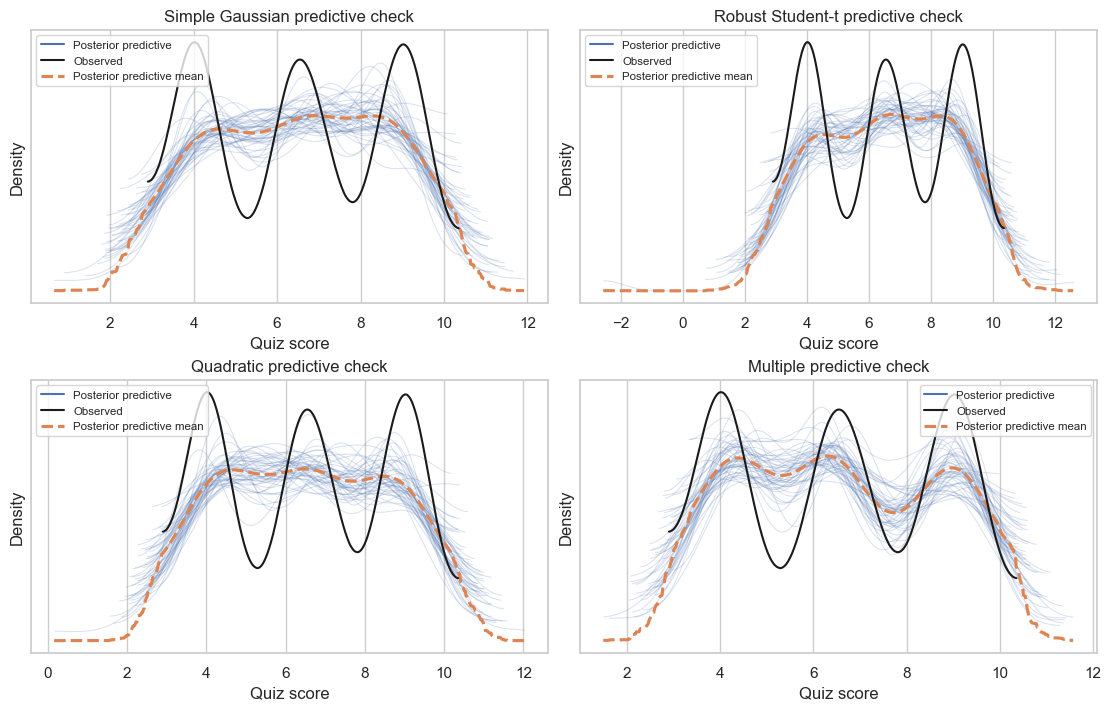

,R2 mean,R2 HDI low,R2 HDI high,max R-hat,min bulk ESS,min tail ESS,divergences
model,,,,,,,
Simple Gaussian,0.881,0.868,0.891,1.000,3476.638,2738.491,0
Robust Student-t,0.881,0.869,0.892,1.001,3264.100,2674.567,0
Quadratic,0.881,0.869,0.892,1.004,1581.644,2171.682,0
Multiple,0.909,0.900,0.916,1.002,1233.135,1434.667,0


In [10]:
models = {
    "Simple Gaussian": (simple_model, simple_fit, ["alpha", "beta", "sigma"]),
    "Robust Student-t": (robust_model, robust_fit, ["alpha", "beta", "sigma", "nu"]),
    "Quadratic": (quadratic_model, quadratic_fit, ["alpha", "beta1", "beta2", "sigma"]),
    "Multiple": (multiple_model, multiple_fit, ["alpha", "beta", "sigma"]),
}
comparison = []
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for (name, (model, fit, names)), ax in zip(models.items(), axes.flat):
    pm.sample_posterior_predictive(fit, model=model, var_names=["score"],
                                   extend_inferencedata=True, random_seed=SEED,
                                   progressbar=False)
    az.plot_ppc(fit, var_names=["score"], num_pp_samples=50, random_seed=SEED, ax=ax)
    ax.set(title=f"{name} predictive check", xlabel="Quiz score", ylabel="Density")
    fitted_mu = draws(fit, "mu")
    mean_var = fitted_mu.var(axis=1)
    residual_var = (y-fitted_mu).var(axis=1)
    r2_draws = mean_var/(mean_var+residual_var)
    r2 = az.r2_score(y, fitted_mu)
    lo, hi = interval(r2_draws)
    diag = az.summary(fit, var_names=names, kind="diagnostics", round_to=4)
    comparison.append([name, r2["r2"], lo, hi, diag["r_hat"].max(),
                       diag["ess_bulk"].min(), diag["ess_tail"].min(),
                       int(fit.sample_stats["diverging"].sum())])
plt.show()
comparison = pd.DataFrame(comparison, columns=["model", "R2 mean", "R2 HDI low", "R2 HDI high",
                                               "max R-hat", "min bulk ESS", "min tail ESS",
                                               "divergences"]).set_index("model")
display(comparison.round(3))

The Bayesian R² means are **0.880** for simple Gaussian, **0.881** for robust, **0.881** for quadratic and **0.909** for multiple regression. The table shows how much uncertainty surrounds each estimate. They describe fit to the same 150 students.

The density overlays compare shape as well as location. The observations are grouped into score bands, so the fitted densities should be checked for how much they smooth those clusters. The observed score SD is 2.10. Average replicated SDs are Simple Gaussian 2.11, Robust Student-t 2.11, Quadratic 2.11, Multiple 2.11. Across the four regressions, the maximum R-hat is 1.004, the minimum bulk ESS is 1233, the minimum tail ESS is 1435, and there are 0 divergences. R-hat near one compares mixing across chains, and effective sample size reflects how much information remains after accounting for correlated draws.

I would use the **multiple regression** as the main description. It captures more variation across the three habits, and its R² interval is above the simple model's interval in this run. I would report the coefficient uncertainty because the predictors overlap heavily. The predictive checks use the observed dataset, so this comparison does not establish which model predicts best on new students.

## Part 3 · Group means for study hours
The unpooled model gives each group an independent Normal(5, 3) mean prior. The hierarchical model estimates a shared center with a Normal(5, 3) prior and a between-group SD with a HalfNormal(3) prior. Both use the same within-group HalfNormal(2) SD prior. I sample the category means directly because all three groups have 50 observations and their means are well informed by the data.

,count,mean,std
student_type,,,
bad,50,2.976,0.535
good,50,5.575,0.546
excellent,50,7.887,0.467


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
group_mu[bad],2.976,0.075,2.839,3.122,0.001,0.001,5290.428,2547.352,1.000
group_mu[good],5.577,0.075,5.433,5.714,0.001,0.001,4595.468,2612.879,1.004
group_mu[excellent],7.885,0.074,7.746,8.027,0.001,0.001,5022.825,2626.753,1.001
sigma,0.522,0.031,0.465,0.580,0.000,0.001,4257.714,2636.223,1.001


Divergences: 0


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
group_mu[bad],2.980,0.075,2.843,3.123,0.001,0.001,5903.058,2596.604,1.002
group_mu[good],5.578,0.075,5.431,5.715,0.001,0.001,5893.440,2959.247,1.001
group_mu[excellent],7.885,0.073,7.742,8.018,0.001,0.001,6135.846,3015.698,1.001
mu_g,5.333,1.398,2.619,7.890,0.023,0.029,3767.429,2646.512,1.003
tau_g,2.842,1.171,1.085,4.996,0.020,0.025,3801.734,3191.691,1.000
sigma,0.522,0.031,0.462,0.577,0.000,0.001,5364.147,2852.604,1.001


Divergences: 0


,count,sample mean,unpooled mean,hierarchical mean,movement toward center
student_type,,,,,
bad,50,2.9756,2.9758,2.9796,0.0038
good,50,5.5755,5.5765,5.5777,-0.0012
excellent,50,7.8873,7.8855,7.8845,0.0010


Hierarchical overall mean: 5.333 hours.
Largest movement toward the center: bad


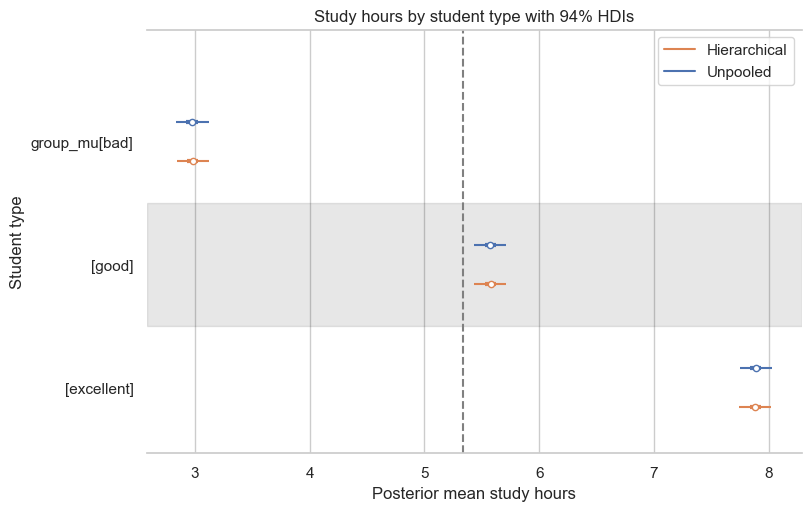

In [11]:
labels = pd.Categorical(students["student_type"], categories=classes).codes
mapping = dict(enumerate(classes))
group_stats = students.groupby("student_type")["study_hours"].agg(["count", "mean", "std"])
group_stats = group_stats.reindex(classes)
display(group_stats.round(3))

with pm.Model(coords={"group": classes}) as unpooled_model:
    group_mu = pm.Normal("group_mu", 5, 3, dims="group")
    sigma = pm.HalfNormal("sigma", 2)
    pm.Normal("hours", group_mu[labels], sigma, observed=x)
    unpooled_fit = sample()

with pm.Model(coords={"group": classes}) as hierarchical_model:
    mu_g = pm.Normal("mu_g", 5, 3)
    tau_g = pm.HalfNormal("tau_g", 3)
    group_mu = pm.Normal("group_mu", mu=mu_g, sigma=tau_g, dims="group")
    sigma = pm.HalfNormal("sigma", 2)
    pm.Normal("hours", group_mu[labels], sigma, observed=x)
    hierarchical_fit = sample()

summary(unpooled_fit, ["group_mu", "sigma"])
summary(hierarchical_fit, ["group_mu", "mu_g", "tau_g", "sigma"])
unpooled_means = draws(unpooled_fit, "group_mu").mean(axis=0)
hierarchical_means = draws(hierarchical_fit, "group_mu").mean(axis=0)
overall_mean = draws(hierarchical_fit, "mu_g").mean()
group_comparison = group_stats[["count", "mean"]].rename(columns={"mean": "sample mean"})
group_comparison["unpooled mean"] = unpooled_means
group_comparison["hierarchical mean"] = hierarchical_means
group_comparison["movement toward center"] = (abs(unpooled_means-overall_mean)
                                              - abs(hierarchical_means-overall_mean))
display(group_comparison.round(4))
print(f"Hierarchical overall mean: {overall_mean:.3f} hours.")
print("Largest movement toward the center:",
      group_comparison["movement toward center"].idxmax())

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
az.plot_forest([unpooled_fit, hierarchical_fit], model_names=["Unpooled", "Hierarchical"],
               var_names=["group_mu"], combined=True, hdi_prob=.94, ax=ax)
ax.axvline(overall_mean, color="gray", linestyle="--")
ax.set(title="Study hours by student type with 94% HDIs",
       xlabel="Posterior mean study hours", ylabel="Student type")
plt.show()

The shared center is **5.333 hours**. The largest movement toward it in this run is for **bad**, from 2.976 to 2.980 hours. The change is small because each category has 50 observations and the group means are well separated. The forest plot shows the uncertainty around each of these means.

Partial pooling lets the other groups inform each mean through the shared center and between-group spread. A small group usually has a less precise sample mean and can move more, although the distances from the center and the estimated spread also matter. Shrinkage can add bias if a genuinely different group has sparse data.

## Part 4 · Bayesian multiclass classification
I split first using stratification and then compute the predictor mean and sample SD from the training rows. Both splits use those same training statistics, which prevents test data from influencing the model.

In [12]:
X_raw = students[features].to_numpy()
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, labels, test_size=.2, stratify=labels, random_state=SEED
)
train_mean = X_train_raw.mean(axis=0)
train_sd = X_train_raw.std(axis=0, ddof=1)
X_train = (X_train_raw-train_mean)/train_sd
X_test = (X_test_raw-train_mean)/train_sd

print("Label mapping:", mapping)
print("Train X and y:", X_train.shape, y_train.shape)
print("Test X and y:", X_test.shape, y_test.shape)
display(pd.DataFrame({"all": np.bincount(labels, minlength=3),
                      "train": np.bincount(y_train, minlength=3),
                      "test": np.bincount(y_test, minlength=3)}, index=classes))
display(pd.DataFrame({"training mean": train_mean, "training SD": train_sd}, index=features))

Label mapping: {0: 'bad', 1: 'good', 2: 'excellent'}
Train X and y: (120, 3) (120,)
Test X and y: (30, 3) (30,)


,all,train,test
bad,50,40,10
good,50,40,10
excellent,50,40,10


,training mean,training SD
study_hours,5.443807,2.064124
sleep_hours,5.120921,1.603464
social_time,3.954438,1.653077


### Softmax and Categorical likelihood
I use `bad` as the reference class and fix its score to zero because adding the same number to every class score leaves Softmax unchanged. The two other classes get Normal(0, 2) intercepts and Normal(0, 1.5) slopes, with predictors on the training-SD scale. These priors regularize the log-odds, which matters if classes are well separated. Softmax normalizes the three exponential scores together. Three independent binary sigmoids can produce probabilities whose sum differs from one.

In [13]:
with pm.Model(coords={"nonbaseline": classes[1:], "predictor": features,
                      "observation": np.arange(len(y_train)), "student_type": classes}) as class_model:
    alpha = pm.Normal("alpha", 0, 2, dims="nonbaseline")
    beta = pm.Normal("beta", 0, 1.5, dims=("predictor", "nonbaseline"))
    other_scores = alpha + X_train @ beta
    scores = pt.concatenate([pt.zeros_like(other_scores[:, :1]), other_scores], axis=1)
    probs = pm.Deterministic("probs", pm.math.softmax(scores, axis=1),
                             dims=("observation", "student_type"))
    pm.Categorical("category", p=probs, observed=y_train, dims="observation")
    class_fit = sample()

summary(class_fit, ["alpha", "beta"])
train_prob_draws = draws(class_fit, "probs")

def check_probs(p):
    assert np.isfinite(p).all()
    assert ((p >= 0) & (p <= 1)).all()
    assert np.allclose(p.sum(axis=-1), 1)

check_probs(train_prob_draws)
print("All training draws produce valid probability vectors.")

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha[good],1.265,0.767,-0.221,2.660,0.017,0.011,1940.285,2398.260,1.001
alpha[excellent],-0.208,1.099,-2.283,1.862,0.023,0.018,2260.028,2308.002,1.001
"beta[study_hours, good]",3.072,0.908,1.378,4.759,0.018,0.014,2541.735,2638.005,1.001
"beta[study_hours, excellent]",2.411,1.223,0.197,4.740,0.022,0.019,3175.277,2684.086,0.999
"beta[sleep_hours, good]",2.589,0.967,0.880,4.495,0.020,0.015,2247.154,2551.230,1.001
"beta[sleep_hours, excellent]",-2.657,1.183,-4.994,-0.551,0.021,0.016,3335.014,3024.168,1.001
"beta[social_time, good]",-2.181,0.919,-3.899,-0.444,0.019,0.014,2440.260,2705.926,1.002
"beta[social_time, excellent]",-2.741,1.166,-4.955,-0.524,0.021,0.019,3156.578,2013.225,1.001


Divergences: 0
All training draws produce valid probability vectors.


### Test predictions and evaluation
For each posterior draw I use its coefficients to calculate a probability vector for each test student. Then I average the probabilities and choose the class with the highest average. This carries parameter uncertainty into the probability estimate.

Test accuracy: 1.000


,precision,recall,f1-score,support
bad,1.0,1.0,1.0,10.0
good,1.0,1.0,1.0,10.0
excellent,1.0,1.0,1.0,10.0
macro avg,1.0,1.0,1.0,30.0
weighted avg,1.0,1.0,1.0,30.0


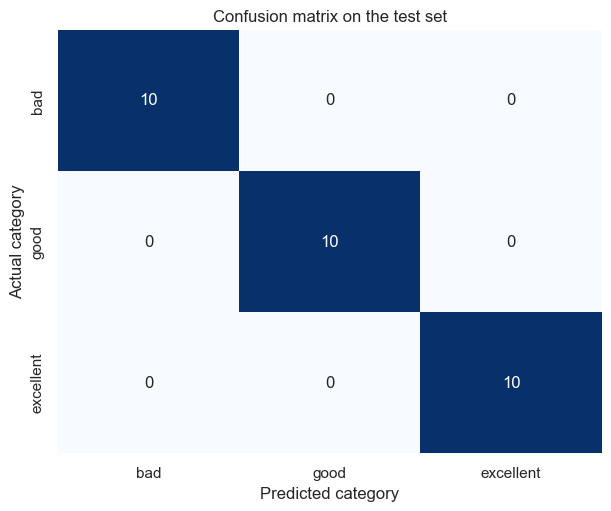

,bad,good,excellent,actual,prediction
0,0.977,0.023,0.000,bad,bad
1,0.000,0.007,0.993,excellent,excellent
2,0.029,0.956,0.015,good,good
3,0.009,0.989,0.002,good,good
4,0.993,0.007,0.001,bad,bad
5,0.027,0.972,0.001,good,good
6,0.976,0.015,0.009,bad,bad
7,0.754,0.236,0.011,bad,bad
8,0.000,0.017,0.983,excellent,excellent
9,0.005,0.994,0.001,good,good


No off-diagonal errors in this test split.
bad: precision 1.00, recall 1.00 on 10 test students.
good: precision 1.00, recall 1.00 on 10 test students.
excellent: precision 1.00, recall 1.00 on 10 test students.


In [14]:
class_alpha = draws(class_fit, "alpha")
class_beta = draws(class_fit, "beta")
test_other_scores = class_alpha[:, None, :] + np.einsum("tf,dfk->dtk", X_test, class_beta)
test_scores = np.concatenate([np.zeros_like(test_other_scores[:, :, :1]), test_other_scores], axis=2)
prob_draws = softmax(test_scores, axis=2)
check_probs(prob_draws)
test_probs = prob_draws.mean(axis=0)
check_probs(test_probs)

predicted = test_probs.argmax(axis=1)
test_accuracy = accuracy_score(y_test, predicted)
print(f"Test accuracy: {test_accuracy:.3f}")
metrics = classification_report(y_test, predicted, labels=np.arange(3), target_names=classes,
                                output_dict=True, zero_division=0)
display(pd.DataFrame({k: metrics[k] for k in classes + ["macro avg", "weighted avg"]}).T.round(3))
matrix = confusion_matrix(y_test, predicted, labels=np.arange(3))
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", vmin=0, cbar=False,
            xticklabels=classes, yticklabels=classes, ax=ax)
ax.set(title="Confusion matrix on the test set", xlabel="Predicted category", ylabel="Actual category")
plt.show()
predictions = pd.DataFrame(test_probs, columns=classes)
predictions["actual"] = [mapping[i] for i in y_test]
predictions["prediction"] = [mapping[i] for i in predicted]
display(predictions.round(3))

mistakes = matrix.copy()
np.fill_diagonal(mistakes, 0)
if mistakes.sum():
    for actual, pred in zip(*np.where(mistakes == mistakes.max())):
        print(f"Most frequent error: {classes[actual]} predicted as {classes[pred]} "
              f"({mistakes[actual, pred]}).")
else:
    print("No off-diagonal errors in this test split.")
for name in classes:
    print(f"{name}: precision {metrics[name]['precision']:.2f}, "
          f"recall {metrics[name]['recall']:.2f} on {int(metrics[name]['support'])} test students.")

Test accuracy is **100.0%**. Class results (bad: precision 1.00, recall 1.00 | good: precision 1.00, recall 1.00 | excellent: precision 1.00, recall 1.00) each use 10 true cases. There are no mistaken category pairs in this split. All three categories are separated equally well on these particular 30 test rows. With a small synthetic test set, this result says little about how the model would perform on a new cohort.

### Probability, odds and log-odds
Probability is the chance of an event. Odds compare its chance to its complement, $p/(1-p)$, and log-odds are the natural logarithm of those odds. For example, $p=0.75$ means odds of 3 to 1 and log-odds of about 1.10.

A positive binary logistic slope increases the odds with the other predictors fixed, and a negative slope decreases them. In the Softmax model $\log(p_a/p_b)$ is the difference of their scores. To compare two non-reference classes I subtract their slopes. Because the probabilities share a denominator, a positive slope relative to the reference does not specify a fixed probability increase.

In [15]:
study_good = class_beta[:, 0, 0]
study_excellent = class_beta[:, 0, 1]
study_excellent_vs_good = study_excellent - study_good
for title, posterior in [("good vs bad", study_good), ("excellent vs bad", study_excellent),
                         ("excellent vs good", study_excellent_vs_good)]:
    print(f"Study hours, {title}, log-odds slope:", estimate(posterior))
    print("Odds multiplier per training SD:", estimate(np.exp(posterior)))
print(f"One training SD of study hours is {train_sd[0]:.2f} hours.")

Study hours, good vs bad, log-odds slope: 3.072 (94% HDI 1.378 to 4.759)
Odds multiplier per training SD: 33.386 (94% HDI 1.536 to 95.013)
Study hours, excellent vs bad, log-odds slope: 2.411 (94% HDI 0.197 to 4.740)
Odds multiplier per training SD: 23.900 (94% HDI 0.166 to 78.379)
Study hours, excellent vs good, log-odds slope: -0.660 (94% HDI -3.190 to 2.259)
Odds multiplier per training SD: 1.486 (94% HDI 0.002 to 5.013)
One training SD of study hours is 2.06 hours.


For a one-SD increase in study hours, the estimated log-odds slopes relative to **bad** are 3.072 (94% HDI 1.378 to 4.759) for **good** and 2.411 (94% HDI 0.197 to 4.740) for **excellent**. For example, using the mean excellent-versus-bad coefficient gives an odds multiplier of $e^{2.411} \approx 11.15$, with sleep and social time fixed. The excellent-versus-good slope is uncertain because its interval includes zero. The observed class separation and the strong study-hours pattern are consistent with those relative odds, although test performance uses all three predictors together.

## Part 5 · Final reflection

1. **Strongest correlation.** Study hours has the strongest absolute correlation with quiz score ($r=0.939$), narrowly ahead of social time ($r=-0.936$). These are one-predictor relationships. The multiple regression slope isolates the association at fixed values of the other habits, and this changes the estimate for study time from 0.954 to 0.507 per hour.

2. **Robust regression.** The Student-t and Gaussian posterior study slopes are 0.955 and 0.954 points per hour. The estimates lead to the same positive association. The Student-t likelihood gives more probability to large residuals, so extreme scores can exert less influence on its line.

3. **Multicollinearity.** Study time and social time have $r=-0.936$, and their fitted slopes move together in the joint posterior. For study time, the 94% HDI is 0.271 points per hour wide after adjustment, compared with 0.109 before adjustment. When students with more study time tend to have less social time, the model has limited information to estimate each slope separately.

4. **Partial pooling.** The unpooled model estimates each group mean with its own prior. The hierarchical model estimates a shared distribution and uses it to inform every group mean. For bad, the posterior mean goes from 2.976 to 2.980 hours, toward the center of 5.333.

5. **Outcome types.** A Gaussian model describes the continuous quiz score as a mean plus residual variation. Student type takes one of three labels, so Softmax produces a probability vector and the Categorical likelihood assigns probability to the observed label.

6. **Limitation.** These are 150 synthetic observations, with only 30 test observations for classification. The results describe associations and test-set prediction within this dataset. They do not establish that asking students to change their hours would cause their quiz scores to change.

### Demo notes

- Trace plots show whether chains explore similar ranges. R-hat, effective sample size and divergences check the sampling process. Posterior predictive plots check the model against the observed scores.
- Regression bands show uncertainty about the fitted mean. A simulated score can vary more because it also includes residual noise.
- The test data are used after fitting. Each posterior draw gives three class probabilities, and the average probability vector is used for classification.

**Assistance disclosure.** OpenAI Codex assisted with drafting, code execution and reviewing the notebook. Results come from the supplied dataset and the fitted models shown above.